# Hydrographs for flood scenarios

In [1]:
# Flood scenarios hydrographs
import os
import glob
import pandas as pd


SIMULATION_DATA_DIR = "/data/westport/data"
BOUNDARY_CONDITIONS_DIR = f"{SIMULATION_DATA_DIR}/flood-mapping-with-ml-main-DATA/DATA/boundary_conditions"
FLOOD_MAPS_DIR = f"{SIMULATION_DATA_DIR}/flood_maps"

def create_indices():
    event_index = {
        0: "July2021",
        1: "Base0",
        2: "Base1",
        3: "Base2",
        4: "Base3",
        5: "Base4",
        6: "Base5",
        7: "Base6",
        8: "Base7",
        9: "Base8", 
    }
    for i in range(1,98):
        event_index[9+i] = f"S{i:02d}"
        
    event_name_map = {
        "July2021": "July_2021",
        "Base0": "Base0_Buller20yrARI_v2",
        "Base1": "Base1_Buller50yrARI_v2",
        "Base2": "Base2_Buller100yrARI",
        "Base3": "Base3_Buller50yrARI_RCP4pt5",
        "Base4": "Base4_Buller50yrARI_RCP6pt0",
        "Base5": "Base5_Buller50yrARI_RCP8pt5",
        "Base6": "Base6_Buller100yrARI_RCP4pt5",
        "Base7": "Base7_Buller100yrARI_RCP6pt0",
        "Base8": "Base8_Buller100yrARI_RCP8pt5"
    }
    
    for i in range(1,98):
        event_name_map[f"S{i:02d}"] = f"S{i:02d}"
    return event_index, event_name_map

event_index_map, event_name_map = create_indices()


In [ ]:
test_events = [0, 6, 9, 11, 15, 16, 17, 18, 29, 65, 72, 81, 83, 84]

def extract_timestep_from_filename(filename):
    # Timestep format is depth_at_2000-01-02_00-00-00.tif, so we need to extract the part after 'depth_at_' and before '.tif'
    timestep_str = filename.split("depth_at_")[1].split(".tif")[0]
    # Convert to datetime object
    timestep_dt = pd.to_datetime(timestep_str, format="%Y-%m-%d_%H-%M-%S")
    return timestep_dt


def preprocess_boundary_conditions():
        boundary_conditions = {} # Store flood map file paths for each event
        
        for event_id in test_events:
    
            event_index = event_index_map[event_id]
            inflow_file = os.path.join(BOUNDARY_CONDITIONS_DIR, f"{event_index}.csv")
            inflow_data = pd.read_csv(inflow_file)
            
      
            # Drop first column as it is just an index column
            # inflow_data = inflow_data.drop(inflow_data.columns[0], axis=1)
            
            event_name = event_name_map[event_index_map[event_id]]
            
            
       
            #Add a column to the inflow data for the corresponding flood map timestamp. If not found add a default value.
            inflow_data['Date_Time'] = pd.to_datetime(inflow_data['Date_Time'])
            
            if event_id == 0:
                inflow_data = inflow_data[inflow_data['Date_Time'] >= pd.to_datetime('2021-07-15 00:00:00')]
            else:
                flood_map_files = glob.glob(f"{FLOOD_MAPS_DIR}/{event_name}_depth_snapshots/depth_at_*.tif")
                flood_map_files.sort()
                
                # Extract the timestamp from the flood map file names and store in a list
                flood_map_timestamps = [extract_timestep_from_filename(file) for file in flood_map_files]
                
                inflow_data['Flood_Map_Available'] = inflow_data['Date_Time'].apply(lambda x: True if x in flood_map_timestamps else False)
                inflow_data['flood_map_file'] = inflow_data['Date_Time'].apply(lambda x: next((file for file in flood_map_files if extract_timestep_from_filename(file) == x), None))
                inflow_data = inflow_data[inflow_data['Flood_Map_Available']]
                inflow_data = inflow_data[inflow_data['Flood_Map_Available']]
                inflow_data.drop(columns=['Flood_Map_Available'], inplace=True)
            
            #if any event has food maps missing let me know
            # missing_flood_maps = inflow_data[~inflow_data['Flood_Map_Available']]
            # if not missing_flood_maps.empty:
            #     print(f"Warning: Event ID {event_id} ({event_name}) has missing flood maps for the following timesteps:")
            #     print(missing_flood_maps[['Date_Time']])
            #drop rows where flood map file is not available
            
            boundary_conditions[event_id] = inflow_data
            # print(f"Event ID: {event_id}, Event Name: {event_name}, Number of timesteps with flood maps: {len(inflow_data)}")
        
    
        #save a separate csv file with the event data map for each event
        # for event_id, inflow_data in boundary_conditions.items():
        #     inflow_data.to_csv(os.path.join(GRAPH_OUTPUT_DIR, "westport",  f"event_{event_id}.csv"), index=False)   
        return boundary_conditions

event_data_map = preprocess_boundary_conditions()



In [ ]:
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import numpy as np
import pandas as pd
import matplotlib.patheffects as pe

PLOT_DIR = "/home/91/23016891/projects/westport-ibw/out"

BG_COL   = "#cccccc"
BG_ALPHA = 0.30

RIVER_COL = "#BF461A"
SEA_COL   = "#1A6FBF"
LABEL_COL = "#333333"

# ── Font sizes (bumped up further) ──────────────────────────────────
FS_AXIS_LABEL  = 17
FS_TICK        = 12
FS_CIRCLE_NUM  = 13   # number inside each circle
FS_OUTLIER     = 16   # July 2021 text label
FS_LEGEND      = 13

test_events = [0, 6, 9, 11, 15, 16, 17, 18, 29, 65, 72, 81, 83, 84]

# Outlier events keep a real text label instead of a numbered circle
OUTLIER_EVENTS = {0}
known_event_names = {0: "July 2021"}

# Assign sequential numbers to the non-outlier (simulated) events
test_event_name_map = {}
sim_counter = 1
for eid in test_events:
    if eid in known_event_names:
        test_event_name_map[eid] = known_event_names[eid]
    else:
        test_event_name_map[eid] = sim_counter  # store the plain number
        sim_counter += 1


def assign_levels(x_positions, ax, min_gap_px=45):
    fig = ax.figure
    fig.canvas.draw()
    trans = ax.transData
    disp_x = np.array([trans.transform((x, 0))[0] for x in x_positions])

    order = np.argsort(disp_x)
    levels = np.zeros(len(x_positions), dtype=int)
    level_last_x = []

    for idx in order:
        x_px = disp_x[idx]
        placed = False
        for lvl, last_x in enumerate(level_last_x):
            if x_px - last_x >= min_gap_px:
                levels[idx] = lvl
                level_last_x[lvl] = x_px
                placed = True
                break
        if not placed:
            levels[idx] = len(level_last_x)
            level_last_x.append(x_px)

    return levels


fig, (ax_r, ax_s) = plt.subplots(2, 1, figsize=(14, 9.5), sharex=True)

# ── Background events ─────────────────────────────────────────────
for eid, df in event_data_map.items():
    if eid in test_events:
        continue
    df = df.copy()
    df["Date_Time"] = pd.to_datetime(df["Date_Time"])
    t = (df["Date_Time"] - df["Date_Time"].iloc[0]).dt.total_seconds() / 3600
    ax_r.plot(t, df["River_flow"], color=BG_COL, lw=0.7, alpha=BG_ALPHA, zorder=1)
    ax_s.plot(t, df["Sea_level"],  color=BG_COL, lw=0.7, alpha=BG_ALPHA, zorder=1)

# ── Test events, single colour per panel ───────────────────────────
valid_test_events = [eid for eid in test_events if eid in event_data_map]

end_points_r, end_points_s = {}, {}
for eid in valid_test_events:
    df = event_data_map[eid].copy()
    df["Date_Time"] = pd.to_datetime(df["Date_Time"])
    t = (df["Date_Time"] - df["Date_Time"].iloc[0]).dt.total_seconds() / 3600

    ax_r.plot(t, df["River_flow"], color=RIVER_COL, lw=1.6, alpha=0.85, zorder=5)
    ax_s.plot(t, df["Sea_level"],  color=SEA_COL,   lw=1.6, alpha=0.85, zorder=5)

    end_points_r[eid] = (t.iloc[-1], df["River_flow"].values[-1])
    end_points_s[eid] = (t.iloc[-1], df["Sea_level"].values[-1])

# ── Labels: numbered circles for sims, text for outliers, stacked to avoid overlap ─
ROW_HEIGHT_FRAC = 0.13

for ax, end_points, line_col in [(ax_r, end_points_r, RIVER_COL), (ax_s, end_points_s, SEA_COL)]:
    y_min_orig, y_max_orig = ax.get_ylim()
    row_height = ROW_HEIGHT_FRAC * (y_max_orig - y_min_orig)

    eids = list(end_points.keys())
    xs = [end_points[eid][0] for eid in eids]

    levels = assign_levels(xs, ax, min_gap_px=45)
    max_level = levels.max()

    for eid, lvl in zip(eids, levels):
        x_orig, y_orig = end_points[eid]
        label = test_event_name_map[eid]
        label_y = y_max_orig + (lvl + 1) * row_height
        is_outlier = eid in OUTLIER_EVENTS

        if is_outlier:
            ax.annotate(
                label,
                xy=(x_orig, y_orig),
                xytext=(x_orig, label_y),
                fontsize=FS_OUTLIER, color=LABEL_COL, ha="center", va="bottom",
                fontweight="bold",
                arrowprops=dict(arrowstyle="-", color=LABEL_COL, lw=0.8, alpha=0.6,
                                 shrinkA=0, shrinkB=3),
                path_effects=[pe.withStroke(linewidth=2.5, foreground="white")],
                annotation_clip=False, zorder=6,
            )
        else:
            ax.annotate(
                str(label),
                xy=(x_orig, y_orig),
                xytext=(x_orig, label_y),
                fontsize=FS_CIRCLE_NUM, color=line_col, ha="center", va="center",
                fontweight="bold",
                bbox=dict(boxstyle="circle,pad=0.35", fc="white", ec=line_col, lw=1.4),
                arrowprops=dict(arrowstyle="-", color=line_col, lw=0.8, alpha=0.7,
                                 shrinkA=9, shrinkB=2),
                annotation_clip=False, zorder=6,
            )

    ax.set_ylim(y_min_orig, y_max_orig + (max_level + 2) * row_height)

ax_r.set_ylabel("River flow (m³/s)", fontsize=FS_AXIS_LABEL)
ax_s.set_ylabel("Sea level (m)",     fontsize=FS_AXIS_LABEL)
ax_s.set_xlabel("Time (h)", fontsize=FS_AXIS_LABEL)
for ax in (ax_r, ax_s):
    ax.tick_params(labelsize=FS_TICK)
    ax.grid(True, lw=0.4, alpha=0.4)

# ── Legend explaining the numbered circles ─────────────────────────
legend_handles = [
    mlines.Line2D([], [], color=RIVER_COL, lw=2.0, label="River flow"),
    mlines.Line2D([], [], color=SEA_COL,   lw=2.0, label="Sea level"),
    mlines.Line2D([], [], marker="o", markersize=14, markerfacecolor="white",
                  markeredgecolor=LABEL_COL, markeredgewidth=1.4, linestyle="None",
                  label=f" Simulations 1–{sim_counter - 1}"),
]
fig.legend(handles=legend_handles, loc="lower center",
           bbox_to_anchor=(0.5, -0.06), ncol=2, fontsize=FS_LEGEND,
           framealpha=0.9, edgecolor="#cccccc", fancybox=False)

fig.tight_layout()
fig.savefig(f"{PLOT_DIR}/fig_bc_test_events.png", bbox_inches="tight", dpi=150)
plt.show()
plt.close(fig)

# Surveyed Flood Depth for July-2021 event

In [3]:
!pip install matplotlib_scalebar
!pip install contextily

  Using cached matplotlib_scalebar-0.9.0-py3-none-any.whl.metadata (18 kB)
Using cached matplotlib_scalebar-0.9.0-py3-none-any.whl (16 kB)
  Using cached geopy-2.4.1-py3-none-any.whl.metadata (6.8 kB)
  Using cached mercantile-1.2.1-py3-none-any.whl.metadata (4.8 kB)
  Using cached geographiclib-2.1-py3-none-any.whl.metadata (1.6 kB)
Using cached geopy-2.4.1-py3-none-any.whl (125 kB)
Using cached geographiclib-2.1-py3-none-any.whl (40 kB)
Using cached mercantile-1.2.1-py3-none-any.whl (14 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [contextily]


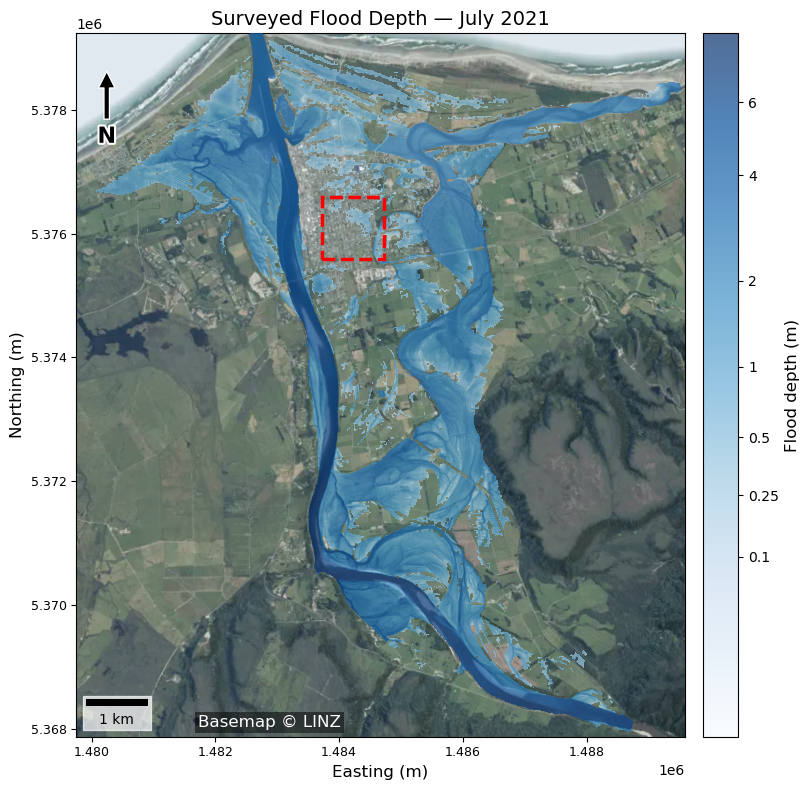

In [45]:
import os
import rasterio
from rasterio.plot import plotting_extent
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patheffects as pe
import numpy as np
import contextily as cx
from matplotlib_scalebar.scalebar import ScaleBar
import matplotlib.colors as mcolors


PLOT_DIR = "/home/91/23016891/projects/westport-ibw/out"

SURVEYED_DEPT_MAP_LOCATION = os.path.join(
    FLOOD_MAPS_DIR,
    "July_2021_depth_snapshots",
    "July_2021_surveyed_flood_depth.tif"
)

LINZ_AERIAL_URL = (
    "https://basemaps.linz.govt.nz/v1/tiles/aerial/"
    "WebMercatorQuad/{z}/{x}/{y}.webp?api=c01kx87w9mvyhr9kanpb3d8f1en"
)

# ---------------------------------------------------------------------
# Read flood raster
# ---------------------------------------------------------------------
with rasterio.open(SURVEYED_DEPT_MAP_LOCATION) as src:
    depth = src.read(1).astype(float)

    if src.nodata is not None:
        depth = np.where(depth == src.nodata, np.nan, depth)

    extent = plotting_extent(src)
    crs = src.crs

# ---------------------------------------------------------------------
# Plot
# ---------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 8))

# 1. Plot the flood overlay FIRST
# This automatically sets the axes limits and sets aspect="equal"
norm = mcolors.PowerNorm(
    gamma=0.3,
    vmin=0.01,
    vmax=np.nanmax(depth),
)

im = ax.imshow(
    depth,
    cmap="Blues",
    norm=norm,
    extent=extent,
    origin="upper",
    alpha=0.7,
    zorder=5,
)

# 2. Add aerial imagery SECOND
# Contextily will now fetch tiles based on the final, aspect-adjusted bounds
cx.add_basemap(
    ax,
    source=LINZ_AERIAL_URL,
    crs=crs,
    zoom="auto",
    reset_extent=True,
    attribution=False,
)

# We use ax.annotate to draw an arrow pointing up, anchored to axes fractions (0 to 1)
ax.annotate(
    "N",
    xy=(0.05, 0.95),       # Arrow tip location (top left)
    xytext=(0.05, 0.87),   # Text location (below the tip)
    xycoords="axes fraction",
    ha="center",
    va="top",
    fontsize=16,
    fontweight="bold",
    color="black",
    # Add a white halo around the "N" text for visibility
    path_effects=[pe.withStroke(linewidth=3, foreground="white")],
    arrowprops=dict(
        facecolor="black",
        edgecolor="white",  # White edge on the arrow for visibility
        width=4,
        headwidth=12,
        headlength=12,
        shrink=0.05,
    ),
    zorder=10,
)

# 4. Add Scale Bar
# Since your CRS is in meters (Eastings/Northings), dx=1 means 1 pixel/unit = 1 meter.
scalebar = ScaleBar(
    dx=1,
    units="m",
    location="lower left",  # You can change to 'lower right', etc.
    box_alpha=0.7,
    color="black",
    box_color="white",
    scale_loc="bottom",
    border_pad=0.5
)
scalebar.set_zorder(10)
ax.add_artist(scalebar)

# Optional: You can explicitly enforce aspect ratio, though imshow usually handles it
ax.set_aspect("equal")

# Colourbar
ticks = [0, 0.1, 0.25, 0.5, 1, 2, 4, 6, np.nanmax(depth)]
ticks = sorted(set(round(t, 2) for t in ticks if t <= np.nanmax(depth)))

cbar = fig.colorbar(
    im,
    ax=ax,
    fraction=0.04,
    pad=0.02,
    ticks=ticks,
)
cbar.set_label("Flood depth (m)", fontsize=12)
cbar.ax.set_yticklabels([f"{t:g}" for t in ticks])

# Attribution
ax.text(
    0.2,
    0.01,
    "Basemap © LINZ",
    transform=ax.transAxes,
    ha="left",
    va="bottom",
    fontsize=12,
    color="white",
    bbox=dict(facecolor="black", alpha=0.5, edgecolor="none", pad=2),
)

from matplotlib.patches import Rectangle





xmin_zoom = 1483728.198719517
xmax_zoom = 1484728.198719517
ymin_zoom = 5375590.031197622
ymax_zoom = 5376590.031197622

zoom_box = Rectangle(
    (xmin_zoom, ymin_zoom),
    xmax_zoom - xmin_zoom,
    ymax_zoom - ymin_zoom,
    fill=False,
    edgecolor="red",
    linewidth=2.5,
    linestyle="--",
    zorder=20,
)

ax.add_patch(zoom_box)

ax.set_title("Surveyed Flood Depth — July 2021", fontsize=14)
ax.set_xlabel("Easting (m)", fontsize=12)
ax.set_ylabel("Northing (m)", fontsize=12)
ax.tick_params(labelsize=9)

fig.tight_layout()

fig.savefig(
    os.path.join(PLOT_DIR, "fig_july2021_surveyed_depth.png"),
    bbox_inches="tight",
    dpi=300,
)

plt.show()
plt.close(fig)

Total entries: 2247
Total houses surveyed: 2247
Unique damage levels: [2. 1. 0. 3.]
Unique damage labels:
  Moderatedamage
  light
  NodamageUnaffected
  Slightdamage
  Severedamage
  moderate
  heavy
  TotaldamageDestroyed
Unique placard colours:
  Red
  1
  Green
  Yellow
  2
  Notapplicable
  4
  3
  5

Damage Number → Label → Colour mapping:
 DamageNb               damage         color  count
      0.0   NodamageUnaffected         Green   1593
      0.0   NodamageUnaffected Notapplicable      2
      0.0   NodamageUnaffected        Yellow      3
      1.0         Slightdamage         Green    114
      1.0         Slightdamage Notapplicable      1
      1.0         Slightdamage        Yellow     47
      1.0                light             1     17
      2.0       Moderatedamage         Green      3
      2.0       Moderatedamage           Red     19
      2.0       Moderatedamage        Yellow    178
      2.0             moderate             1     18
      2.0             modera

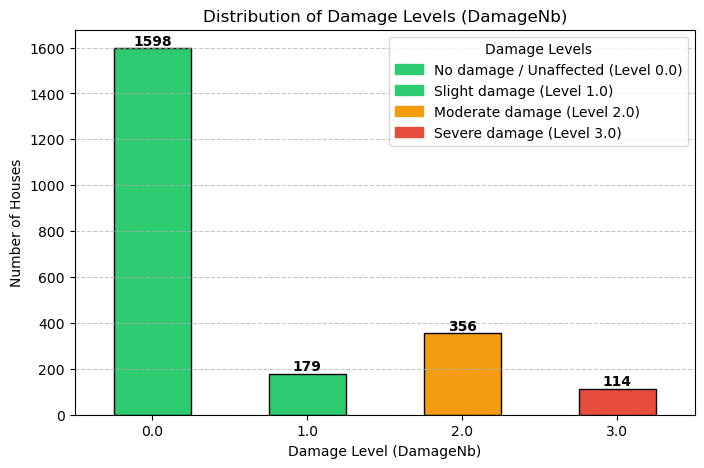

In [46]:
#Damage survey
import geopandas as gpd


PROJECT_ROOT = "/home/91/23016891/projects/westport"
ANALYSIS_DIR = f"{PROJECT_ROOT}/out/"
PLACRD_FILE_PATH = "/data/westport/data/Impact-based_data/obs_placard.gpkg"
placards = gpd.read_file(PLACRD_FILE_PATH)
placards = placards.to_crs(epsg=4326)

#make sure that the directory exists
import os
os.makedirs(ANALYSIS_DIR, exist_ok=True)

#get some stats about the data
# Total houses surveyed
total_entries = len(placards)
#number of unique houses (by building ID)
total_houses = placards["building_id"].nunique()
print(f"Total entries: {total_entries}")
print(f"Total houses surveyed: {total_houses}")

damage_numbers_unique = placards["DamageNb"].unique()
print(f"Unique damage levels: {damage_numbers_unique}")
print("Unique damage labels:")
for label in placards["damage"].unique():
    print(f"  {label}")
print("Unique placard colours:")
for colour in placards["color"].unique():
    print(f"  {colour}")
    
# Association between damage number, damage label and placard colour
association = (placards
               .groupby(["DamageNb", "damage", "color"])
               .size()
               .reset_index(name="count")
               .sort_values("DamageNb"))

print("\nDamage Number → Label → Colour mapping:")
print(association.to_string(index=False))

#Find the MBIE damage levels and their corresponding placard colours
mbie_damage_levels = placards[placards["DamageNb"].isin([0.0, 1.0, 2.0, 3.0])]["DamageNb"].unique()
print(f"MBIE Damage Levels: {mbie_damage_levels}")

for level in mbie_damage_levels:
    damage_label = association[association["DamageNb"] == level]["damage"].iloc[0]
    color = association[association["DamageNb"] == level]["color"].iloc[0]
    print(f"  Damage Level {level}: Label: {damage_label}, Color: {color}")


# Count of houses by damage level
damage_counts = placards["DamageNb"].value_counts().sort_index()
print("House counts by damage level:")


damage_level_and_colour = {
    0.0: {"label": "No damage / Unaffected", "color": "#2ecc71"},  # Green
    1.0: {"label": "Slight damage", "color": "#2ecc71"},  # Green
    2.0: {"label": "Moderate damage", "color": "#f39c12"},  # Yellow
    3.0: {"label": "Severe damage", "color": "#e74c3c"}   # Red
}

#plot the distribution of damage levels
plt.figure(figsize=(8, 5))
#use the colours from the damage_level_and_colour mapping for the bars
damage_counts.plot(kind="bar", color=[damage_level_and_colour.get(level, {"color": "#aaaaaa"})["color"] for level in damage_counts.index], edgecolor="black")
plt.title("Distribution of Damage Levels (DamageNb)")
plt.xlabel("Damage Level (DamageNb)")
plt.ylabel("Number of Houses")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.7)

#Add the number of houses on top of each bar
for index, value in enumerate(damage_counts):
    plt.text(index, value, str(value), ha="center", va="bottom", fontweight="bold")

# Add a legend
handles = [plt.Rectangle((0, 0), 1, 1, color=info["color"]) for level, info in damage_level_and_colour.items()]
labels = [f"{info['label']} (Level {level})" for level, info in damage_level_and_colour.items()]
plt.legend(handles, labels, title="Damage Levels", loc="upper right")

#save the plot as a PNG file
plt.savefig(f"{ANALYSIS_DIR}/damage_distribution.png", dpi=300, bbox_inches="tight")

In [2]:
import geopandas as gpd
PLACRD_FILE_PATH = "/data/westport/data/Impact-based_data/obs_placard.gpkg"
placards = gpd.read_file(PLACRD_FILE_PATH)
placards = placards.to_crs(epsg=4326)

In [8]:
total_entries = len(placards)
#number of unique houses (by building ID)
total_houses = placards["building_id"].nunique()
placards["DamageNb"].isnull().sum()
placards.columns

Index(['damage', 'color', 'source', 'building_id', 'DamageNb', 'geometry'], dtype='str')

/tmp/ipykernel_962109/3667992491.py:42: UserWarning: Legend does not support handles for PatchCollection instances.
See: https://matplotlib.org/stable/tutorials/intermediate/legend_guide.html#implementing-a-custom-legend-handler
  ax.legend(title="Damage Level", loc="upper right", framealpha=0.9)
/tmp/ipykernel_962109/3667992491.py:42: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(title="Damage Level", loc="upper right", framealpha=0.9)


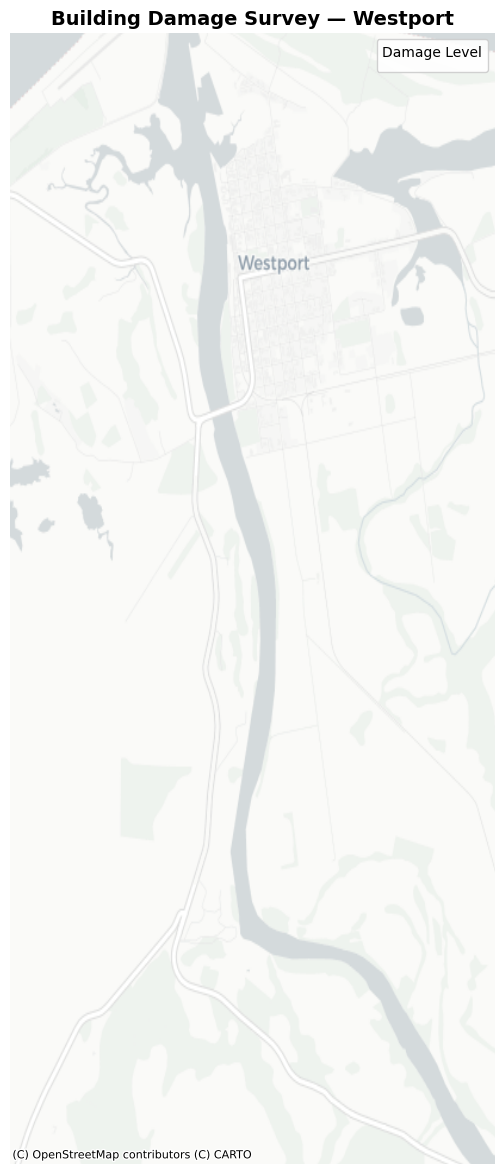

In [47]:
import matplotlib.pyplot as plt
import contextily as ctx  # optional, for a basemap - pip install contextily if missing

# Map each row to its damage colour (reuse your damage_level_and_colour dict)
placards["plot_color"] = placards["DamageNb"].map(
    lambda x: damage_level_and_colour.get(x, {"color": "#aaaaaa"})["color"]
)

fig, ax = plt.subplots(figsize=(12, 12))

# Plot each damage level separately so the legend works cleanly
for level, info in damage_level_and_colour.items():
    subset = placards[placards["DamageNb"] == level]
    if len(subset) == 0:
        continue
    subset.plot(
        ax=ax,
        color=info["color"],
        markersize=25,
        edgecolor="black",
        linewidth=0.3,
        label=f"{info['label']} (Level {level})"
    )

# Plot any rows with damage levels not in the mapping (e.g. NaN, or >3) in grey
other = placards[~placards["DamageNb"].isin(damage_level_and_colour.keys())]
if len(other) > 0:
    other.plot(ax=ax, color="#aaaaaa", markersize=25, edgecolor="black",
               linewidth=0.3, label="Other / Unknown")

# Optional basemap (requires data in web mercator - reproject a copy for plotting)
try:
    placards_3857 = placards.to_crs(epsg=3857)
    ax.set_xlim(placards_3857.total_bounds[[0, 2]])
    ax.set_ylim(placards_3857.total_bounds[[1, 3]])
    ctx.add_basemap(ax, crs=placards_3857.crs.to_string(), source=ctx.providers.CartoDB.Positron)
except Exception as e:
    print(f"Basemap skipped: {e}")

ax.set_title("Building Damage Survey — Westport", fontsize=14, fontweight="bold")
ax.set_axis_off()
ax.legend(title="Damage Level", loc="upper right", framealpha=0.9)

plt.tight_layout()
plt.savefig(f"{ANALYSIS_DIR}/damage_map.png", dpi=300, bbox_inches="tight")
plt.show()

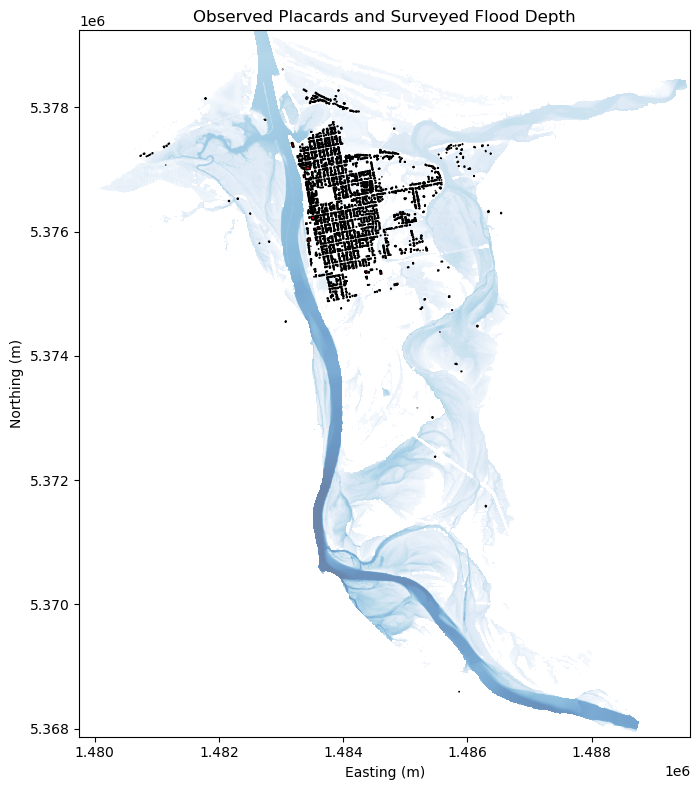

In [48]:
import geopandas as gpd
import matplotlib.pyplot as plt
import rasterio
from rasterio.plot import plotting_extent
import numpy as np

PLACARD_FILE_PATH = "/data/westport/data/Impact-based_data/obs_placard.gpkg"

# ---------------------------------------------------------------------
# Read flood raster
# ---------------------------------------------------------------------
with rasterio.open(SURVEYED_DEPT_MAP_LOCATION) as src:
    depth = src.read(1).astype(float)

    if src.nodata is not None:
        depth = np.where(depth == src.nodata, np.nan, depth)

    extent = plotting_extent(src)
    flood_crs = src.crs

# ---------------------------------------------------------------------
# Read placards
# ---------------------------------------------------------------------
placards = gpd.read_file(PLACARD_FILE_PATH)

# Reproject to flood CRS
placards = placards.to_crs(flood_crs)

# ---------------------------------------------------------------------
# Plot
# ---------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 8))

ax.imshow(
    depth,
    extent=extent,
    origin="upper",
    cmap="Blues",
    alpha=0.6,
)

# Plot placards
placards.plot(
    ax=ax,
    color="red",
    edgecolor="black",
    markersize=30,
    zorder=10,
)

# Restrict view to flood extent
ax.set_xlim(extent[0], extent[1])
ax.set_ylim(extent[2], extent[3])

ax.set_title("Observed Placards and Surveyed Flood Depth")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.set_aspect("equal")

plt.tight_layout()
plt.show()

649


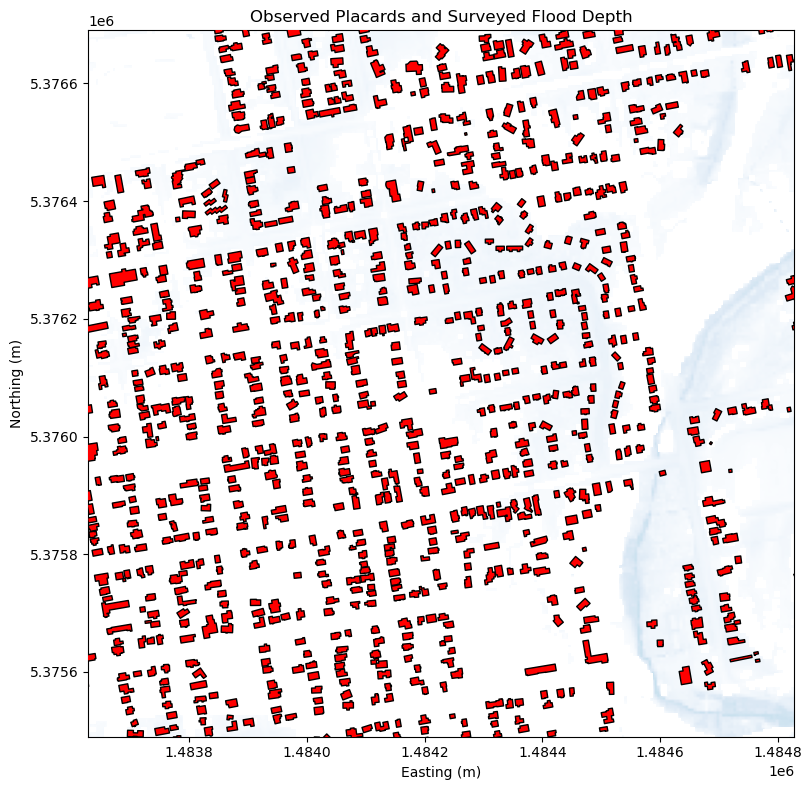

In [40]:
import numpy as np
import geopandas as gpd
from shapely.geometry import box

# placards should already be in EPSG:2193
placards = placards.to_crs(2193)

# ------------------------------------------------------------------
# Create 1 km grid
# ------------------------------------------------------------------
cell_size = 1000  # metres

xmin, ymin, xmax, ymax = placards.total_bounds

xgrid = np.arange(xmin, xmax + cell_size, cell_size)
ygrid = np.arange(ymin, ymax + cell_size, cell_size)

cells = []
counts = []

for x in xgrid[:-1]:
    for y in ygrid[:-1]:
        poly = box(x, y, x + cell_size, y + cell_size)
        n = placards.within(poly).sum()

        cells.append(poly)
        counts.append(n)

grid = gpd.GeoDataFrame(
    {"count": counts},
    geometry=cells,
    crs=placards.crs,
)

# Cell with highest concentration
best_cell = grid.loc[grid["count"].idxmax()]

print(best_cell["count"])

xmin, ymin, xmax, ymax = best_cell.geometry.bounds

pad = 100  # metres


fig, ax = plt.subplots(figsize=(10, 8))


ax.set_xlim(xmin - pad, xmax + pad)
ax.set_ylim(ymin - pad, ymax + pad)

ax.imshow(
    depth,
    extent=extent,
    origin="upper",
    cmap="Blues",
    alpha=0.6,
)

# Plot placards
placards.plot(
    ax=ax,
    color="red",
    edgecolor="black",
    markersize=30,
    zorder=10,
)


ax.set_title("Observed Placards and Surveyed Flood Depth")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.set_aspect("equal")

plt.tight_layout()
plt.show()

1484118.198719517
1484238.198719517
5376780.031197622
5376900.031197622
Buildings shown: 18


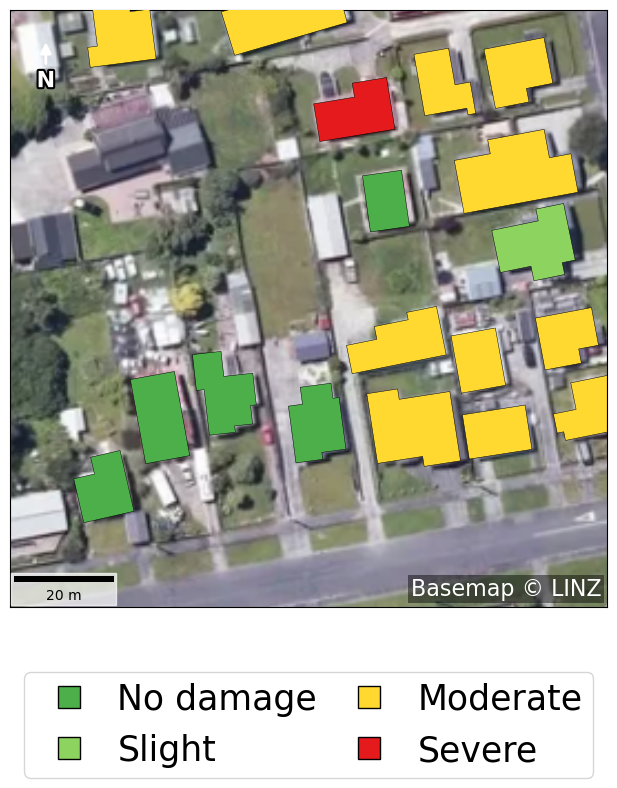

In [87]:
import os
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import contextily as cx
from shapely.geometry import box
from matplotlib_scalebar.scalebar import ScaleBar
from matplotlib.lines import Line2D

# ---------------------------------------------------------------------
# Paths
# ---------------------------------------------------------------------
PROJECT_ROOT = "/home/91/23016891/projects/westport-ibw"
PLOT_DIR = f"{PROJECT_ROOT}/out"

PLACARD_FILE = "/data/westport/data/Impact-based_data/obs_placard.gpkg"

LINZ_AERIAL_URL = (
    "https://basemaps.linz.govt.nz/v1/tiles/aerial/"
    "WebMercatorQuad/{z}/{x}/{y}.webp?api=c01kx87w9mvyhr9kanpb3d8f1en"
)

# ---------------------------------------------------------------------
# Read data
# ---------------------------------------------------------------------
placards = gpd.read_file(PLACARD_FILE)

# Convert to NZTM2000
placards = placards.to_crs(2193)

# ---------------------------------------------------------------------
# Find busiest 1 km × 1 km grid cell
# ---------------------------------------------------------------------
CELL_SIZE = 100  # metres

xmin, ymin, xmax, ymax = placards.total_bounds

# Compute centroids only for grid indexing
centroids = placards.geometry.centroid

placards["grid_x"] = (
    (centroids.x - xmin) // CELL_SIZE
).astype(int)

placards["grid_y"] = (
    (centroids.y - ymin) // CELL_SIZE
).astype(int)

grid_counts = (
    placards
    .groupby(["grid_x", "grid_y"])
    .size()
    .reset_index(name="count")
)

best = grid_counts.loc[grid_counts["count"].idxmax()]

gx = int(best.grid_x)
gy = int(best.grid_y)

xmin_zoom = xmin + gx * CELL_SIZE
xmax_zoom = xmin_zoom + CELL_SIZE

ymin_zoom = ymin + gy * CELL_SIZE
ymax_zoom = ymin_zoom + CELL_SIZE



# small padding
pad = 10

xmin_zoom -= pad
xmax_zoom += pad
ymin_zoom -= pad
ymax_zoom += pad

print(xmin_zoom)
print(xmax_zoom)
print(ymin_zoom)
print(ymax_zoom)


# ---------------------------------------------------------------------
# Select houses in this window
# ---------------------------------------------------------------------
bbox = box(xmin_zoom, ymin_zoom, xmax_zoom, ymax_zoom)

subset = placards.clip(bbox)

print(f"Buildings shown: {len(subset)}")

# ---------------------------------------------------------------------
# Damage colours
# ---------------------------------------------------------------------
damage_colours = {
    0: "#4daf4a",   # No damage
    1: "#8dd35f",   # Slight
    2: "#ffd92f",   # Moderate
    3: "#e41a1c",   # Severe
}

damage_labels = {
    0: "No damage",
    1: "Slight",
    2: "Moderate",
    3: "Severe",
}

# ---------------------------------------------------------------------
# Figure
# ---------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8,8))

ax.set_xlim(xmin_zoom, xmax_zoom)
ax.set_ylim(ymin_zoom, ymax_zoom)

# ---------------------------------------------------------------------
# Basemap
# ---------------------------------------------------------------------
cx.add_basemap(
    ax,
    source=LINZ_AERIAL_URL,
    crs="EPSG:2193",
    zoom=18,
    reset_extent=True,
    attribution=False,
)

# ---------------------------------------------------------------------
# Plot buildings
# ---------------------------------------------------------------------
for level in sorted(damage_colours.keys()):

    pts = subset[subset["DamageNb"] == level]

    if len(pts) == 0:
        continue

    pts.plot(
        ax=ax,
        color=damage_colours[level],
        edgecolor="black",
        linewidth=0.35,
        markersize=35,
        zorder=5,
    )

# ---------------------------------------------------------------------
# Legend
# ---------------------------------------------------------------------
handles = []

for level in sorted(damage_colours.keys()):

    handles.append(
        Line2D(
            [],
            [],
            marker="s",
            linestyle="",
            markerfacecolor=damage_colours[level],
            markeredgecolor="black",
            markersize=16,
            label=damage_labels[level],
        )
    )

legend = ax.legend(
    handles=handles,
    # title="Observed building damage",
    loc="upper center",
    bbox_to_anchor=(0.5, -0.08),   # Centered below the axes
    ncol=2,     
    # nrow=2,# One row with four categories
    # frameon=True,
    # framealpha=0.95,
    fontsize=25,
    title_fontsize=20,
    columnspacing=0.5,
    handletextpad=0.4,
    borderpad=0.3,
)

# ---------------------------------------------------------------------
# North arrow
# ---------------------------------------------------------------------
ax.annotate(
    "N",
    xy=(0.06, 0.95),
    xytext=(0.06, 0.87),
    xycoords="axes fraction",
    ha="center",
    fontsize=16,
    fontweight="bold",
    color="white",
    path_effects=[
        pe.withStroke(linewidth=3, foreground="black")
    ],
    arrowprops=dict(
        arrowstyle="-|>",
        lw=2,
        color="white",
    ),
)

# ---------------------------------------------------------------------
# Scale bar
# ---------------------------------------------------------------------
scalebar = ScaleBar(
    dx=1,
    units="m",
    location="lower left",
    box_alpha=0.7,
    box_color="white",
    color="black",
)

ax.add_artist(scalebar)

# ---------------------------------------------------------------------
# Attribution
# ---------------------------------------------------------------------
ax.text(
    0.99,
    0.01,
    "Basemap © LINZ",
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=16,
    color="white",
    bbox=dict(
        facecolor="black",
        alpha=0.45,
        edgecolor="none",
        pad=2,
    ),
)
ax.set_xticks([])
ax.set_yticks([])

# ---------------------------------------------------------------------
# Labels
# ---------------------------------------------------------------------
# ax.set_title("Surveyed Building Damage (1 km × 1 km)", fontsize=14)

# ax.set_xlabel("Easting (m)")
# ax.set_ylabel("Northing (m)")

ax.set_aspect("equal")

plt.tight_layout()

os.makedirs(PLOT_DIR, exist_ok=True)

plt.savefig(
    os.path.join(PLOT_DIR, "fig_observed_building_damage.png"),
    dpi=300,
    bbox_inches="tight",
)

plt.show()




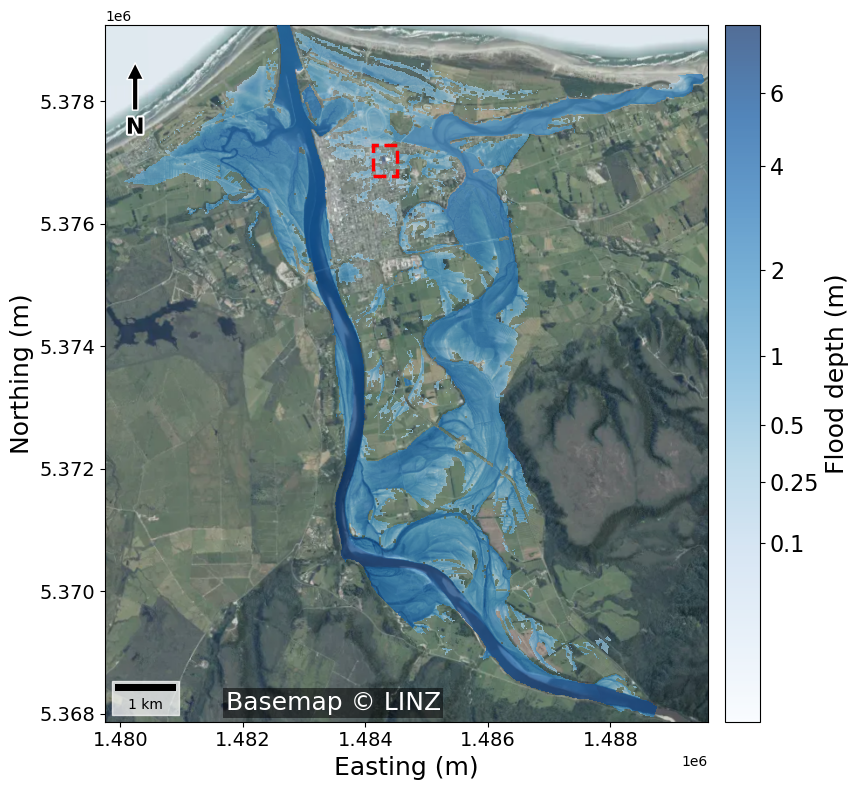

In [76]:

import os
import rasterio
from rasterio.plot import plotting_extent
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patheffects as pe
import numpy as np
import contextily as cx
from matplotlib_scalebar.scalebar import ScaleBar
import matplotlib.colors as mcolors


PLOT_DIR = "/home/91/23016891/projects/westport-ibw/out"

SURVEYED_DEPT_MAP_LOCATION = os.path.join(
    FLOOD_MAPS_DIR,
    "July_2021_depth_snapshots",
    "July_2021_surveyed_flood_depth.tif"
)

LINZ_AERIAL_URL = (
    "https://basemaps.linz.govt.nz/v1/tiles/aerial/"
    "WebMercatorQuad/{z}/{x}/{y}.webp?api=c01kx87w9mvyhr9kanpb3d8f1en"
)

# ---------------------------------------------------------------------
# Read flood raster
# ---------------------------------------------------------------------
with rasterio.open(SURVEYED_DEPT_MAP_LOCATION) as src:
    depth = src.read(1).astype(float)

    if src.nodata is not None:
        depth = np.where(depth == src.nodata, np.nan, depth)

    extent = plotting_extent(src)
    crs = src.crs

# ---------------------------------------------------------------------
# Plot
# ---------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 8))

# 1. Plot the flood overlay FIRST
# This automatically sets the axes limits and sets aspect="equal"
norm = mcolors.PowerNorm(
    gamma=0.3,
    vmin=0.01,
    vmax=np.nanmax(depth),
)

im = ax.imshow(
    depth,
    cmap="Blues",
    norm=norm,
    extent=extent,
    origin="upper",
    alpha=0.7,
    zorder=5,
)

# 2. Add aerial imagery SECOND
# Contextily will now fetch tiles based on the final, aspect-adjusted bounds
cx.add_basemap(
    ax,
    source=LINZ_AERIAL_URL,
    crs=crs,
    zoom="auto",
    reset_extent=True,
    attribution=False,
)

# We use ax.annotate to draw an arrow pointing up, anchored to axes fractions (0 to 1)
ax.annotate(
    "N",
    xy=(0.05, 0.95),       # Arrow tip location (top left)
    xytext=(0.05, 0.87),   # Text location (below the tip)
    xycoords="axes fraction",
    ha="center",
    va="top",
    fontsize=16,
    fontweight="bold",
    color="black",
    # Add a white halo around the "N" text for visibility
    path_effects=[pe.withStroke(linewidth=3, foreground="white")],
    arrowprops=dict(
        facecolor="black",
        edgecolor="white",  # White edge on the arrow for visibility
        width=4,
        headwidth=12,
        headlength=12,
        shrink=0.05,
    ),
    zorder=10,
)

# 4. Add Scale Bar
# Since your CRS is in meters (Eastings/Northings), dx=1 means 1 pixel/unit = 1 meter.
scalebar = ScaleBar(
    dx=1,
    units="m",
    location="lower left",  # You can change to 'lower right', etc.
    box_alpha=0.7,
    color="black",
    box_color="white",
    scale_loc="bottom",
    border_pad=0.5
)
scalebar.set_zorder(10)
ax.add_artist(scalebar)

# Optional: You can explicitly enforce aspect ratio, though imshow usually handles it
ax.set_aspect("equal")

# Colourbar
ticks = [0, 0.1, 0.25, 0.5, 1, 2, 4, 6, np.nanmax(depth)]
ticks = sorted(set(round(t, 2) for t in ticks if t <= np.nanmax(depth)))

cbar = fig.colorbar(
    im,
    ax=ax,
    fraction=0.04,
    pad=0.02,
    ticks=ticks,
)
cbar.set_label("Flood depth (m)", fontsize=18)
cbar.ax.set_yticklabels([f"{t:g}" for t in ticks], fontsize=16)

# Attribution
ax.text(
    0.2,
    0.01,
    "Basemap © LINZ",
    transform=ax.transAxes,
    ha="left",
    va="bottom",
    fontsize=18,
    color="white",
    bbox=dict(facecolor="black", alpha=0.5, edgecolor="none", pad=2),
)

from matplotlib.patches import Rectangle


# 1484118.198719517
# 1484238.198719517
# 5376780.031197622
# 5376900.031197622
xmin_zoom = 1484118.198719517
xmax_zoom = 1484518.198719517
ymin_zoom = 5376780.031197622
ymax_zoom = 5377280.031197622

zoom_box = Rectangle(
    (xmin_zoom, ymin_zoom),
    xmax_zoom - xmin_zoom,
    ymax_zoom - ymin_zoom,
    fill=False,
    edgecolor="red",
    linewidth=2.5,
    linestyle="--",
    zorder=20,
)

ax.add_patch(zoom_box)

# ax.set_title("Surveyed Flood Depth — July 2021", fontsize=14)
ax.set_xlabel("Easting (m)", fontsize=18)
ax.set_ylabel("Northing (m)", fontsize=18)
ax.tick_params(labelsize=14)

fig.tight_layout()

fig.savefig(
    os.path.join(PLOT_DIR, "fig_july2021_surveyed_depth.png"),
    bbox_inches="tight",
    dpi=300,
)

plt.show()
plt.close(fig)

# Analysis Of Exposed Objects

In [ ]:
import geopandas as gpd
import rasterio
import numpy as np

BUILDING_FILE_PATH = f"{SIMULATION_DATA_DIR}/exposure/buildings.geojson"
ROADS_FILE_PATH = f"{SIMULATION_DATA_DIR}/exposure/road_network.gpkg"
SAMPLE_FLOOD_MAP = os.path.join(
    FLOOD_MAPS_DIR,
    "Base0_Buller20yrARI_v2_depth_snapshots",
    "depth_at_2000-01-02_00-00-00.tif"
)

# Read raster
with rasterio.open(SAMPLE_FLOOD_MAP) as src:
    depth = src.read(1).astype(float)
    transform = src.transform

# Domain mask
domain_mask = ~np.isnan(depth)

# Read buildings
buildings = gpd.read_file(BUILDING_FILE_PATH)
roads = gpd.read_file(ROADS_FILE_PATH)

# Ensure CRS matches the raster
with rasterio.open(SAMPLE_FLOOD_MAP) as src:
    if buildings.crs != src.crs:
        buildings = buildings.to_crs(src.crs)
        roads = roads.to_crs(src.crs)

# Representative point inside each building
points = buildings.representative_point()
road_points = roads.representative_point()

inside = []
inside_roads = []

for pt in points:
    row, col = rasterio.transform.rowcol(transform, pt.x, pt.y)

    if (
        0 <= row < domain_mask.shape[0]
        and 0 <= col < domain_mask.shape[1]
    ):
        inside.append(domain_mask[row, col])
    else:
        inside.append(False)
        
for pt in road_points:
    row, col = rasterio.transform.rowcol(transform, pt.x, pt.y)

    if (
        0 <= row < domain_mask.shape[0]
        and 0 <= col < domain_mask.shape[1]
    ):
        inside_roads.append(domain_mask[row, col])
    else:
        inside_roads.append(False)        


buildings_in_domain = buildings[np.array(inside)]
roads_in_domain = roads[np.array(inside_roads)]

print(f"Buildings in computational domain: {len(buildings_in_domain)}")
print(f"Roads in computational domain: {len(roads_in_domain)}")

Buildings in computational domain: 5556
Roads in computational domain: 632


In [100]:
from rasterio.features import shapes
from shapely.geometry import shape

# Extract domain polygons
geoms = [
    shape(geom)
    for geom, value in shapes(
        domain_mask.astype(np.uint8),
        mask=domain_mask,
        transform=transform
    )
    if value == 1
]

domain = gpd.GeoDataFrame(geometry=geoms, crs=buildings.crs)

/data/miniconda3/envs/westport-ibw-env/lib/python3.11/site-packages/rasterio/features.py:129: RuntimeWarning: DeprecationWarning: 'Memory' driver is deprecated since GDAL 3.11. Use 'MEM' onwards. Further messages of this type will be suppressed.
  yield from _shapes(source, mask, connectivity, transform)


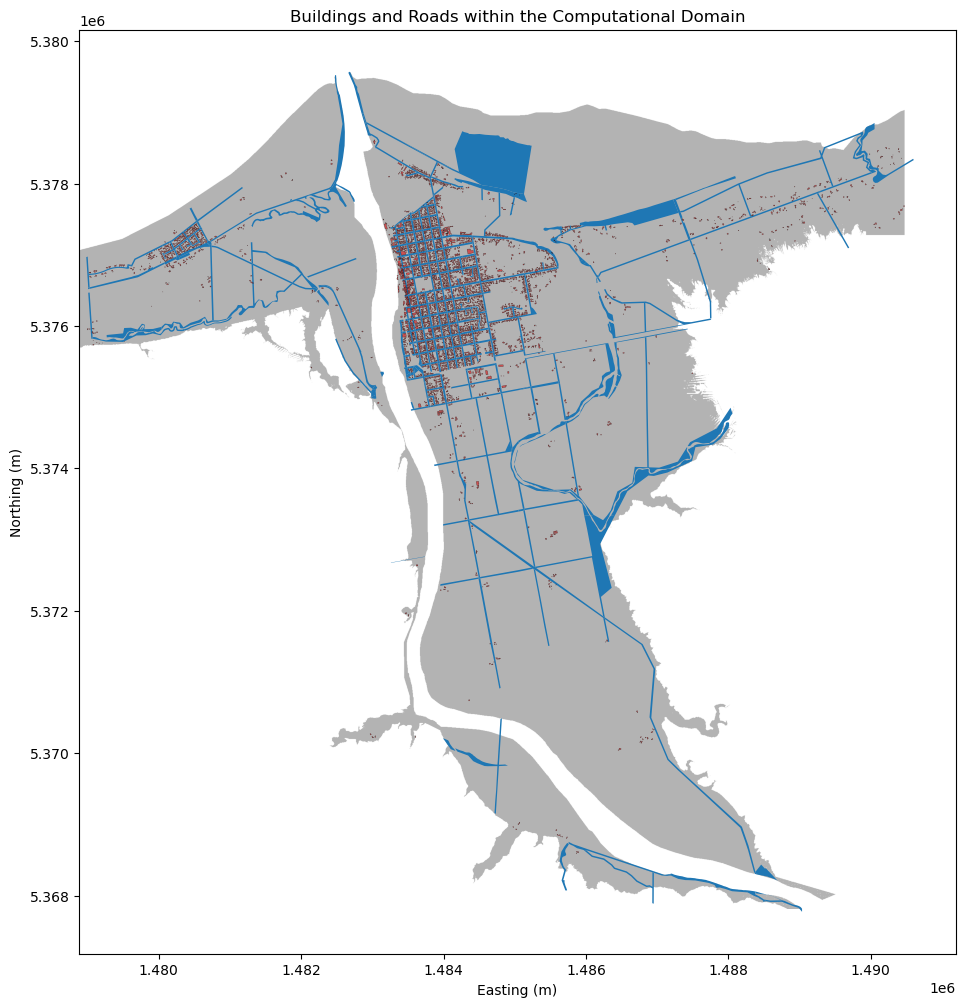

In [101]:
import matplotlib.pyplot as plt
from rasterio.plot import plotting_extent

fig, ax = plt.subplots(figsize=(12, 12))

# Plot computational domain
extent = plotting_extent(depth, transform)
ax.imshow(
    domain_mask,
    extent=extent,
    origin="upper",
    cmap="Greys",
    alpha=0.3
)

# Plot roads
roads_in_domain.plot(
    ax=ax,
    color="tab:blue",
    linewidth=0.5,
    label="Roads"
)

# Plot buildings
buildings_in_domain.plot(
    ax=ax,
    facecolor="tab:red",
    edgecolor="black",
    linewidth=0.2,
    alpha=0.7,
    label="Buildings"
)

ax.set_title("Buildings and Roads within the Computational Domain")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.set_aspect("equal")

plt.show()

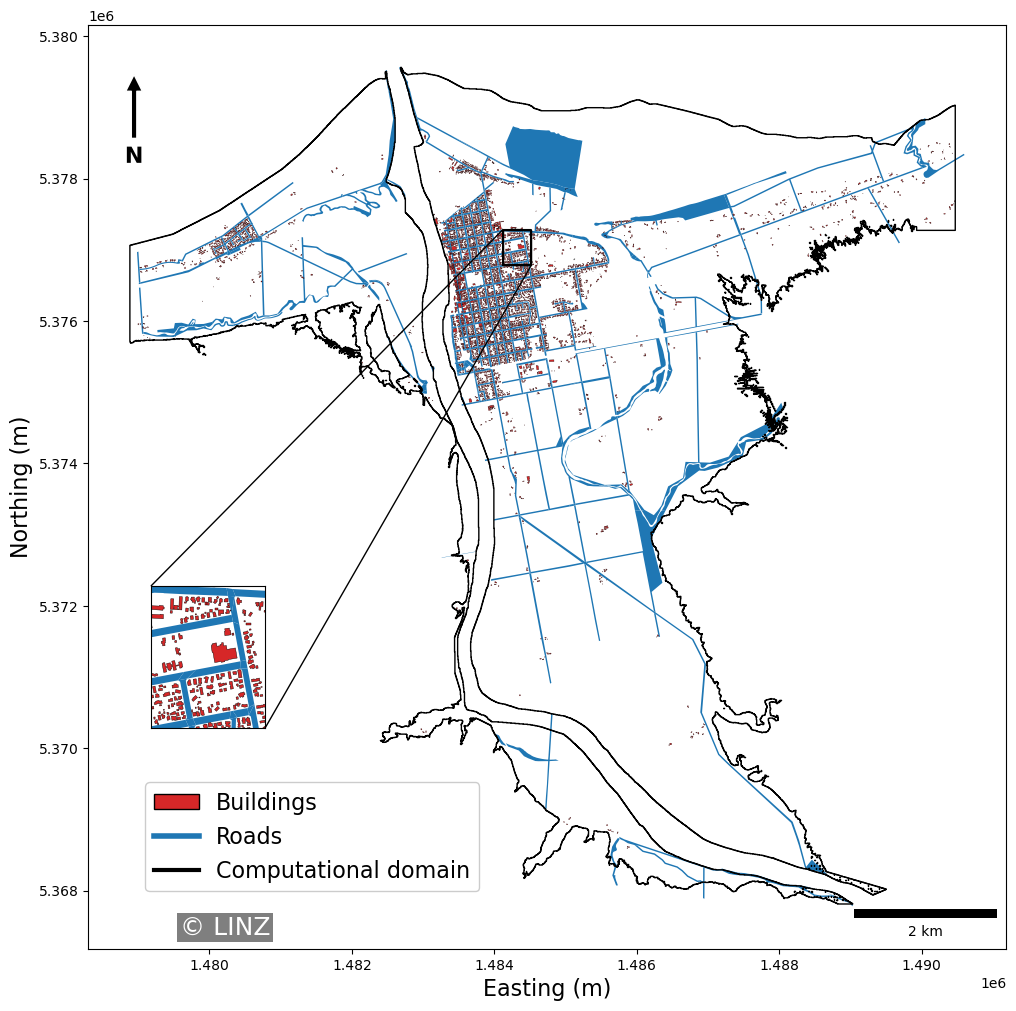

In [127]:
from mpl_toolkits.axes_grid1.inset_locator import zoomed_inset_axes, mark_inset
from matplotlib.patches import Patch


fig, ax = plt.subplots(figsize=(12, 12))

# Plot the full map
domain.boundary.plot(ax=ax, color="black", linewidth=1)
roads_in_domain.plot(ax=ax, color="tab:blue", linewidth=0.5)
buildings_in_domain.plot(
    ax=ax,
    facecolor="tab:red",
    edgecolor="black",
    linewidth=0.2,
)

ax.set_aspect("equal")

# ------------------------------------------------------------------
# Choose the area to zoom (replace with coordinates you want)
# ------------------------------------------------------------------
xmin = 1484118.198719517
xmax = 1484518.198719517
ymin = 5376780.031197622
ymax = 5377280.031197622

# Draw rectangle on main plot
ax.plot(
    [xmin, xmax, xmax, xmin, xmin],
    [ymin, ymin, ymax, ymax, ymin],
    color="black",
    linewidth=1.5,
)

# ------------------------------------------------------------------
# Create inset
# ------------------------------------------------------------------
axins = zoomed_inset_axes(ax, zoom=4,
    bbox_to_anchor=(-0.8, -0.6, 1, 1),
    bbox_transform=ax.transAxes)

domain.boundary.plot(ax=axins, color="black", linewidth=1)
roads_in_domain.plot(ax=axins, color="tab:blue", linewidth=0.8)
buildings_in_domain.plot(
    ax=axins,
    facecolor="tab:red",
    edgecolor="black",
    linewidth=0.3,
)

# Attribution
ax.text(
    0.1,
    0.01,
    "© LINZ",
    transform=ax.transAxes,
    ha="left",
    va="bottom",
    fontsize=18,
    color="white",
    bbox=dict(facecolor="black", alpha=0.5, edgecolor="none", pad=2),
)

scalebar = ScaleBar(
    dx=1,
    units="m",
    location="lower right",  # You can change to 'lower right', etc.
    box_alpha=0.7,
    color="black",
    box_color="white",
    scale_loc="bottom",
    border_pad=0.5
)
scalebar.set_zorder(10)
ax.add_artist(scalebar)

ax.annotate(
    "N",
    xy=(0.05, 0.95),       # Arrow tip location (top left)
    xytext=(0.05, 0.87),   # Text location (below the tip)
    xycoords="axes fraction",
    ha="center",
    va="top",
    fontsize=16,
    fontweight="bold",
    color="black",
    # Add a white halo around the "N" text for visibility
    path_effects=[pe.withStroke(linewidth=3, foreground="white")],
    arrowprops=dict(
        facecolor="black",
        edgecolor="white",  # White edge on the arrow for visibility
        width=4,
        headwidth=12,
        headlength=12,
        shrink=0.05,
    ),
    zorder=10,
)


axins.set_xlim(xmin, xmax)
axins.set_ylim(ymin, ymax)
axins.set_xticks([])
axins.set_yticks([])
axins.set_aspect("equal")

legend_handles = [
    Patch(
        facecolor="tab:red",
        edgecolor="black",
        label="Buildings"
    ),
    Line2D(
        [0], [0],
        color="tab:blue",
        linewidth=4,
        label="Roads"
    ),
    Line2D(
        [0], [0],
        color="black",
        linewidth=3,
        label="Computational domain"
    ),
]

ax.legend(
    handles=legend_handles,
    loc="lower left",
    frameon=True,
    framealpha=1.0,
    bbox_to_anchor=(0.05, 0.05), 
    fontsize=16
)

# Connect inset to rectangle
mark_inset(ax, axins, loc1=2, loc2=4, fc="none", ec="black")
ax.set_xlabel("Easting (m)", fontsize=16)
ax.set_ylabel("Northing (m)", fontsize=16)

fig.savefig(
    os.path.join(PLOT_DIR, "exposure_of_buildings_and_roads.png"),
    bbox_inches="tight",
    dpi=300,
)


plt.show()

In [ ]:
# Surveyed flood depth and placard data intersection. See where surveyed depth is not available eventhough the houses are affected

